# XGBoost Classification with Heart Disease Dataset

**Gradient Boosting** builds a model one tree at a time. Each new tree tries to improve the predictions made by the trees already built.

For classification, the model commonly minimizes **log loss**


At each stage, a new tree is added to the current model:
$$
F_{t+1}(x) = F_t(x) + \eta \cdot h_t(x)
$$

where:

- $F_t(x)$ is the current model score.
- $h_t(x)$ is the new decision tree.
- $\eta$ is the learning rate

**Simple interpretation:** Each new tree makes a small correction to the current model.

For binary classification, the final model score is converted into a probability, such as the probability of heart disease.

---

## What is XGBoost?

**XGBoost (Extreme Gradient Boosting)** is an efficient implementation of gradient boosting.

It includes several useful improvements:
- **Regularization**: Controls model complexity and helps reduce overfitting.
- **Parallelization**: Speeds up calculations used to find the best tree splits.
- **Missing Values**: Learns which branch missing values should follow.
- **Tree Pruning**: Removes branches that do not improve the model enough.
- **Column Subsampling**: Allows each tree to use a selection of features.

For simplicity, we leave these settings at their default values and focus on tuning three key hyperparameters:

- `n_estimators`: Number of boosting rounds.
- `max_depth`: Maximum depth of a tree.
- `learning_rate`: Step size shrinkage used to prevent overfitting.

---

## Role of the Learning Rate ($ \eta $)

The **learning rate** controls how much each new tree changes the model.

| Learning Rate | Behavior                                                   |
|---------------|------------------------------------------------------------|
| Larger ($ \eta \approx 0.3 $)  | Learns faster and usually needs fewer trees, but may overfit                             |
| Smaller ($ \eta \approx 0.01 $) | Learns more gradually and usually needs more trees |

The learning rate and number of trees should be considered together:

- **Smaller learning rate → usually more trees**
- **Larger learning rate → usually fewer trees**

---

## Evaluating the Classification Model

Classification models can be evaluated using:

- **Accuracy:** The proportion of predictions that the model classified correctly.
- **Confusion matrix:** A table comparing the predicted classes with the actual classes.

For heart disease classification, the confusion matrix shows:

- **True negative:** Correctly predicted no heart disease.
- **True positive:** Correctly predicted heart disease.
- **False positive:** Predicted heart disease when it was not present.
- **False negative:** Predicted no heart disease when it was present.

---

## Summary
Gradient Boosting adds trees sequentially to improve the current model. XGBoost makes this process more efficient and adds controls that can reduce overfitting.

For this classification example, XGBoost produces the estimated probability of:

- 0: No heart disease
- 1: Heart disease


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score
from xgboost import XGBClassifier

# Load the dataset
data_url = "https://raw.githubusercontent.com/qcif-training/decision-tree-methods/main/heart.csv"
df = pd.read_csv(data_url)

df = (
    df.drop(columns=["id", "dataset"])
      .rename(columns={"num": "target"})
)

df["target"] = (df["target"] > 0).astype(int)

#converts categorical text data into numerical columns using one-hot encoding technique, drop redundant data sex_male=0 means female
df = pd.get_dummies(df, drop_first=True, dtype=int)
df = df.fillna(df.median(numeric_only=True))

# Split the prepared dataset into features and target
X = df.drop("target", axis=1)
y = df["target"]

# Keep 30% of the data aside for testing, stratified sampling for 0 and 1 class, stratify=y
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30,  random_state=42
)
print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")

Training rows: 644
Test rows: 276



We will focus on three key hyperparameters:
- `n_estimators`: Number of boosting rounds.
- `max_depth`: Maximum depth of a tree.
- `learning_rate`: Step size shrinkage used to prevent overfitting.

We’ll also evaluate model performance and interpret it using SHAP (SHapley Additive exPlanations).


## 🔧 Hyperparameter Tuning: `n_estimators`

The `n_estimators` parameter defines the number of boosting rounds (trees). Increasing it can improve performance but might lead to overfitting.


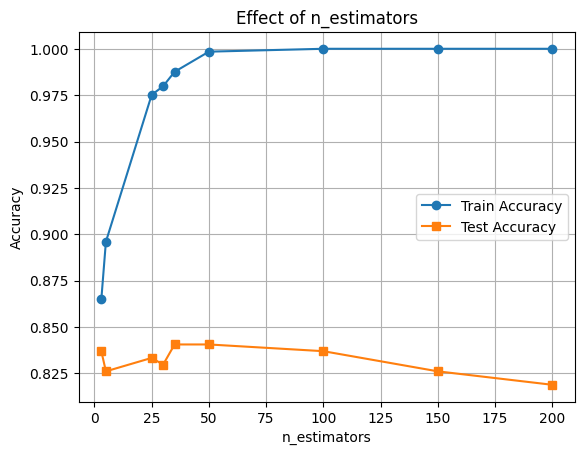

In [2]:
estimators = [3, 5, 25, 30, 35, 50, 100, 150, 200]
train_scores, test_scores = [], []

for n in estimators:
    clf = XGBClassifier(n_estimators=n, eval_metric='logloss')
    clf.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, clf.predict(X_train)))
    test_scores.append(accuracy_score(y_test, clf.predict(X_test)))

plt.plot(estimators, train_scores, marker='o', label='Train Accuracy')
plt.plot(estimators, test_scores, marker='s', label='Test Accuracy')
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.title('Effect of n_estimators')
plt.legend()
plt.grid(True)
plt.show()


## 🔧 Hyperparameter Tuning: `max_depth`

The `max_depth` parameter controls the complexity of each tree. Deeper trees can learn more complex patterns but may overfit.


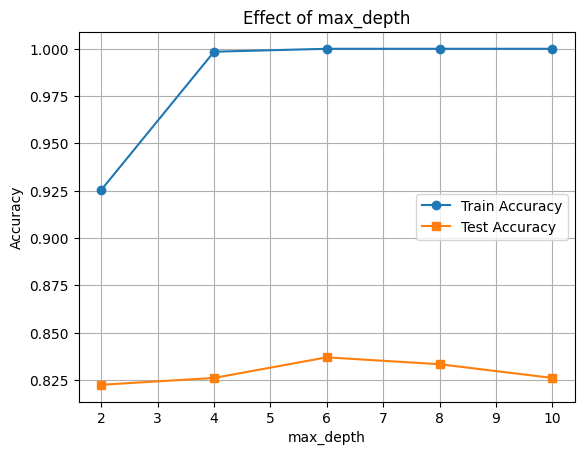

In [3]:
depths = [2, 4, 6, 8, 10]
train_scores, test_scores = [], []

for d in depths:
    clf = XGBClassifier(max_depth=d, eval_metric='logloss')
    clf.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, clf.predict(X_train)))
    test_scores.append(accuracy_score(y_test, clf.predict(X_test)))

plt.plot(depths, train_scores, marker='o', label='Train Accuracy')
plt.plot(depths, test_scores, marker='s', label='Test Accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.title('Effect of max_depth')
plt.legend()
plt.grid(True)
plt.show()


## 🔧 Hyperparameter Tuning: `learning_rate`

The `learning_rate` parameter shrinks the contribution of each tree. Lower values require more trees but improve generalization.


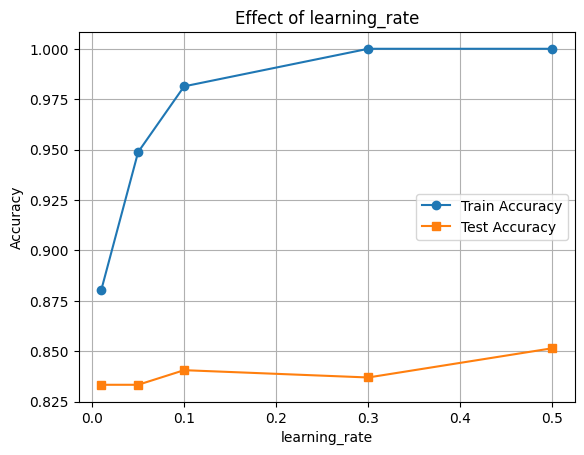

In [4]:
rates = [0.01, 0.05, 0.1, 0.3, 0.5]
train_scores, test_scores = [], []

for rate in rates:
    clf = XGBClassifier(learning_rate=rate, eval_metric='logloss')
    clf.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, clf.predict(X_train)))
    test_scores.append(accuracy_score(y_test, clf.predict(X_test)))

plt.plot(rates, train_scores, marker='o', label='Train Accuracy')
plt.plot(rates, test_scores, marker='s', label='Test Accuracy')
plt.xlabel('learning_rate')
plt.ylabel('Accuracy')
plt.title('Effect of learning_rate')
plt.legend()
plt.grid(True)
plt.show()


## ✅ Final Model with Selected Hyperparameters

We will now train one final tree using a moderate depth and larger leaves. These settings keep the tree readable and reduce overfitting.

In [5]:
final_clf = XGBClassifier(
    n_estimators=50,
    max_depth=6,
    learning_rate=0.5,
    eval_metric='logloss'
    )
final_clf.fit(X_train, y_train)

# Accuracy
train_acc = final_clf.score(X_train, y_train)
test_acc = final_clf.score(X_test, y_test)

print(f"Train Accuracy: {train_acc:.3f}")
print(f"Test Accuracy: {test_acc:.3f}")

Train Accuracy: 1.000
Test Accuracy: 0.837


## Evaluating the Classification Model - Confusion Matrix
A confusion matrix is a table used to describe the performance of a classification model.

              precision    recall  f1-score   support

  No disease       0.80      0.82      0.81       120
     Disease       0.86      0.85      0.85       156

    accuracy                           0.84       276
   macro avg       0.83      0.84      0.83       276
weighted avg       0.84      0.84      0.84       276



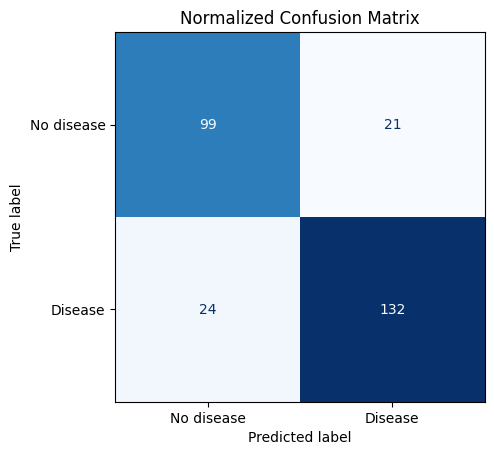

In [6]:

y_pred = final_clf.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["No disease", "Disease"]))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
                                        display_labels=["No disease", "Disease"],
                                        cmap="Blues", colorbar=False)

plt.title("Normalized Confusion Matrix")
plt.show()


## 🧠 Feature Importance with SHAP

We'll use SHAP (SHapley Additive exPlanations) to understand how different features contribute to the model's predictions.

This helps us:
- Identify the most influential features
- Understand direction and magnitude of impact


### 📊 Interpreting the SHAP Summary Plot

The SHAP summary plot visualizes how each feature contributes to the model's output across all samples. Here's what each component means:

| Element                      | Description                                                                                      |
|-----------------------------|--------------------------------------------------------------------------------------------------|
| **Y-axis (Feature Names)**  | Features are sorted by overall importance (top = most important).                              |
| **X-axis (SHAP value)**     | The impact of that feature on the model's prediction.                                           |
| **Each Dot**                | A single row/sample in the dataset.                                                             |
| **Color (Dot Hue)**         | The feature value for that sample — red = high, blue = low.                                    |
| **Direction of SHAP Value**| Positive SHAP value pushes the prediction toward the positive class (e.g., "disease" class).    |
|                             | Negative SHAP value pushes it toward the negative class (e.g., "no disease").                   |

**🧠 Example Interpretation:**  
If the “Age” feature has mostly red dots (high values) with positive SHAP values, it means higher ages are pushing predictions toward the positive class.


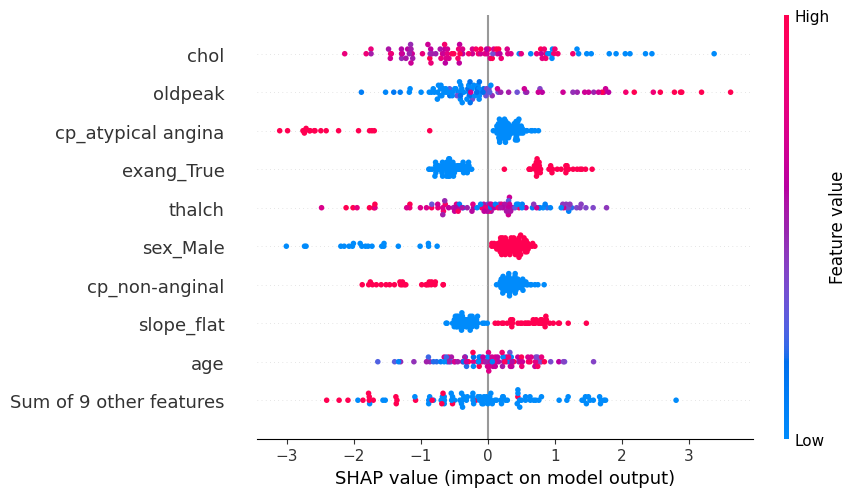

In [7]:
import shap

# Select the first 100 test records
X_sample = X_test.head(100)

# Create an explainer that supports categorical tree splits
explainer = shap.TreeExplainer(
    final_clf,
    feature_perturbation="tree_path_dependent"
)

# Calculate and display SHAP values
shap_values = explainer(X_sample)
# shap.summary_plot(shap_values, X_sample)
shap.plots.beeswarm(shap_values)